In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Загрузка данных
df = pd.read_csv('creditcard.csv')

y = df['Class']
X = df.drop(columns=['Class'])

In [ ]:
# Сначала отделяем Test (20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Затем из оставшегося отделяем Val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

# Сброс индексов
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

print(f"Train: {X_train.shape}, фрод: {y_train.sum()}")
print(f"Val:   {X_val.shape}, фрод: {y_val.sum()}")
print(f"Test:  {X_test.shape}, фрод: {y_test.sum()}")

Train: (170883, 30), фрод: 295
Val:   (56962, 30), фрод: 99
Test:  (56962, 30), фрод: 98


In [3]:
scores = []

print("Обучение моделей...")
for depth in [4, 5, 6, 7, 8]:
    for s in [1, 5, 10, 15, 20, 50, 100, 200]:
        dt = DecisionTreeClassifier(
            max_depth=depth, 
            min_samples_leaf=s, 
            class_weight='balanced', 
            random_state=42
        )
        dt.fit(X_train, y_train)
        y_proba = dt.predict_proba(X_val)[:, 1]
        
        pr_auc = average_precision_score(y_val, y_proba)
        scores.append((depth, s, pr_auc))

# Создаем DataFrame и сортируем
df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'pr_auc'])
df_scores_sorted = df_scores.sort_values(by='pr_auc', ascending=False)

print("\nТоп-5 лучших комбинаций по PR-AUC:")
print(df_scores_sorted.head(5).to_string(index=False))

Обучение моделей...

Топ-5 лучших комбинаций по PR-AUC:
 max_depth  min_samples_leaf   pr_auc
         6                50 0.718454
         8                20 0.714642
         7                50 0.714214
         8                50 0.713983
         8                15 0.709905


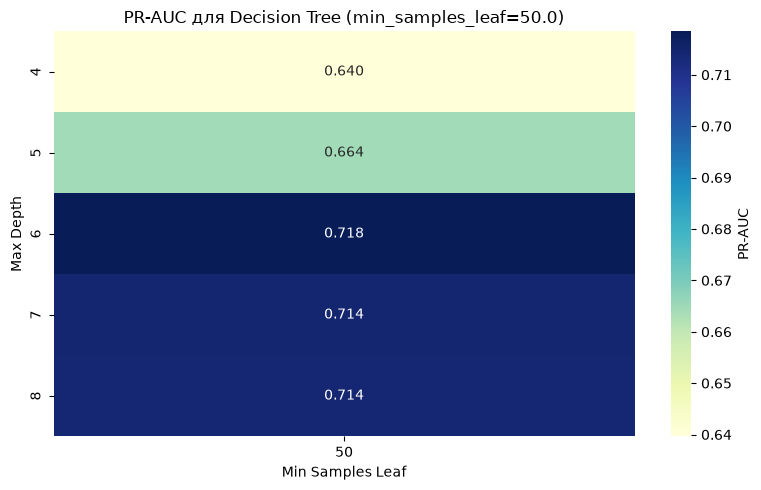

In [4]:
# Берем лучший min_samples_leaf для графика
best_s = df_scores_sorted.iloc[0]['min_samples_leaf'] 
df_filtered = df_scores[df_scores['min_samples_leaf'] == best_s]

# Строим pivot
df_pivot = df_filtered.pivot(
    index='max_depth', 
    columns='min_samples_leaf', 
    values='pr_auc'
)

plt.figure(figsize=(8, 5))
sns.heatmap(df_pivot, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={'label': 'PR-AUC'})
plt.title(f'PR-AUC для Decision Tree (min_samples_leaf={best_s})')
plt.xlabel('Min Samples Leaf')
plt.ylabel('Max Depth')
plt.tight_layout()
plt.show()

In [5]:
# Берем лучшие параметры из GridSearch
best_params = df_scores_sorted.iloc[0]
best_depth = int(best_params['max_depth'])
best_s = int(best_params['min_samples_leaf'])
print(f"Лучшие параметры: max_depth={best_depth}, min_samples_leaf={best_s}")

# Обучаем на train
dt_val = DecisionTreeClassifier(
    max_depth=best_depth, 
    min_samples_leaf=best_s, 
    class_weight='balanced', 
    random_state=42
)
dt_val.fit(X_train, y_train)
y_val_proba = dt_val.predict_proba(X_val)[:, 1]

# Подбор порога
print(f"\n{'Threshold':<12} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 45)

best_threshold = 0
best_f1 = 0

for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_val_pred = (y_val_proba >= t).astype(int)
    p = precision_score(y_val, y_val_pred, zero_division=0)
    r = recall_score(y_val, y_val_pred, zero_division=0)
    f = f1_score(y_val, y_val_pred, zero_division=0)
    
    print(f"{t:<12.1f} {p:>10.4f} {r:>10.4f} {f:>10.4f}")
    
    if f > best_f1:
        best_f1 = f
        best_threshold = t

print(f"\nЛучший порог (по F1): {best_threshold} (F1 = {best_f1:.4f})")

Лучшие параметры: max_depth=6, min_samples_leaf=50

Threshold     Precision     Recall         F1
---------------------------------------------
0.1              0.0521     0.8485     0.0982
0.2              0.0521     0.8485     0.0982
0.3              0.0521     0.8485     0.0982
0.4              0.0521     0.8485     0.0982
0.5              0.1436     0.8485     0.2456
0.6              0.1436     0.8485     0.2456
0.7              0.1436     0.8485     0.2456
0.8              0.1436     0.8485     0.2456
0.9              0.1864     0.8283     0.3043

Лучший порог (по F1): 0.9 (F1 = 0.3043)


In [6]:
# Выводим правила лучшего дерева (топ-3 уровня)
print("\nПравила лучшего дерева:")
feature_names = X_train.columns.tolist()
print(export_text(dt_val, feature_names=feature_names, max_depth=3))


Правила лучшего дерева:
|--- V14 <= -1.81
|   |--- V12 <= -1.94
|   |   |--- V9 <= 1.27
|   |   |   |--- V17 <= 1.53
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- V17 >  1.53
|   |   |   |   |--- class: 1
|   |   |--- V9 >  1.27
|   |   |   |--- class: 1
|   |--- V12 >  -1.94
|   |   |--- V4 <= 2.00
|   |   |   |--- V26 <= -0.14
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- V26 >  -0.14
|   |   |   |   |--- class: 0
|   |   |--- V4 >  2.00
|   |   |   |--- V19 <= -0.13
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- V19 >  -0.13
|   |   |   |   |--- class: 0
|--- V14 >  -1.81
|   |--- V4 <= 1.45
|   |   |--- V20 <= -1.03
|   |   |   |--- V1 <= -2.02
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- V1 >  -2.02
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- V20 >  -1.03
|   |   |   |--- Amount <= 1096.49
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- Amount >  1096.49
|   |   |  

In [ ]:
# 1. Обучаем на train+val
dt_final = DecisionTreeClassifier(
    max_depth=best_depth, 
    min_samples_leaf=best_s, 
    class_weight='balanced', 
    random_state=42
)
dt_final.fit(X_train_full, y_train_full)

# 2. Предсказания на тесте с лучшим порогом
y_test_proba = dt_final.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= best_threshold).astype(int)

# 3. Метрики
print(f"=== DECISION TREE (FINAL, threshold={best_threshold}) ===")
print(f"PR AUC   : {average_precision_score(y_test, y_test_proba):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred):.4f}")
print(f"F1       : {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_test_proba):.4f}")

=== DECISION TREE (FINAL, threshold=0.9) ===
PR AUC   : 0.5956
Precision: 0.2401
Recall   : 0.8061
F1       : 0.3700
ROC AUC  : 0.9122
